# Problem 2 — Transformer from Scratch
**DNN Programming Assignment | Implementation and Experiments**

Run from the `problem2/` folder, top to bottom (Restart & Run All). The HAR data is read from `../problem1/data/har/UCI HAR Dataset`; Tiny Shakespeare is downloaded into `data/`.

All numbers in this notebook are produced by the cells below. Compute budgets are reduced for CPU execution and are stated next to each experiment.

## 0. Setup and reproducibility

In [45]:
import math, random, time, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
torch.set_num_threads(6)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path("."); DATA = ROOT/"data"; FIG = ROOT/"figures"
DATA.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
print("Device:", DEVICE, "PyTorch:", torch.__version__)

Device: cpu PyTorch: 2.15.0


## 1. Task 1 — Scaled dot-product attention

For queries Q, keys K and values V, attention scores are `QKᵀ/√dₖ`. Softmax converts scores into weights; the weighted sum of V is the context. The mask convention below is **True = allowed**.

In [46]:
def scaled_dot_product_attention(Q, K, V, mask=None, dropout_p=0.0, training=False):
    # Q: (..., Lq, D), K: (..., Lk, D), V: (..., Lk, Dv)
    d_k=Q.shape[-1]
    scores=torch.matmul(Q,K.transpose(-2,-1))/math.sqrt(d_k)
    if mask is not None:
        scores=scores.masked_fill(~mask.bool(),torch.finfo(scores.dtype).min)
    weights=torch.softmax(scores,dim=-1)
    if dropout_p and training: weights=F.dropout(weights,p=dropout_p)
    context=torch.matmul(weights,V)
    return context,weights

# Numerical verification against PyTorch's reference operation
q=torch.randn(2,3,5,8); k=torch.randn(2,3,7,8); v=torch.randn(2,3,7,6)
out,w=scaled_dot_product_attention(q,k,v)
ref=F.scaled_dot_product_attention(q,k,v)
assert torch.allclose(out,ref,atol=1e-5)
assert torch.allclose(w.sum(-1),torch.ones_like(w.sum(-1)),atol=1e-6)
print("Reference comparison and row-sum checks passed.")

Reference comparison and row-sum checks passed.


In [47]:
# Causal mask: each position can attend to itself and earlier positions.
L=5
causal=torch.tril(torch.ones(L,L,dtype=torch.bool))
q=k=v=torch.randn(1,1,L,8)
_,cw=scaled_dot_product_attention(q,k,v,mask=causal)
assert torch.all(cw.masked_select(~causal)==0)
print("Causal future-weight check passed.")

Causal future-weight check passed.


### 1.1 Hand-checkable 3-token example

The instructor's official example must be checked against these values (see README). The values below are a small causal example chosen for hand computation: with d_k = 2, the scores are `QKᵀ/√2`. The code result is compared with an independent loop implementation of the same equations.

In [48]:
Qh = torch.tensor([[[1., 0.], [0., 1.], [1., 1.]]])   # (1, 3, 2)
Kh = Qh.clone()
Vh = torch.tensor([[[1., 2.], [3., 4.], [5., 6.]]])   # (1, 3, 2)
causal3 = torch.tril(torch.ones(3, 3, dtype=torch.bool))
ctx_h, w_h = scaled_dot_product_attention(Qh, Kh, Vh, mask=causal3)

# Independent loop implementation (one query at a time, causal prefix only)
ref = torch.zeros_like(Vh); ref_w = torch.zeros(1, 3, 3)
for i in range(3):
    s = torch.tensor([float(Qh[0, i] @ Kh[0, j]) / math.sqrt(2) for j in range(i + 1)])
    p = torch.softmax(s, 0)
    ref_w[0, i, :i + 1] = p
    ref[0, i] = (p[:, None] * Vh[0, :i + 1]).sum(0)
assert torch.allclose(ctx_h, ref, atol=1e-6) and torch.allclose(w_h, ref_w, atol=1e-6)
print("Attention weights (rows = queries):\n", w_h[0].numpy().round(4))
print("Context output:\n", ctx_h[0].numpy().round(4))
print("Hand-example code check passed.")

Attention weights (rows = queries):
 [[1.     0.     0.    ]
 [0.3302 0.6698 0.    ]
 [0.2483 0.2483 0.5035]]
Context output:
 [[1.     2.    ]
 [2.3395 3.3395]
 [3.5105 4.5105]]
Hand-example code check passed.



### Manual calculation of causal attention

**Query and key vectors**

- Token 1: [1, 0]
- Token 2: [0, 1]
- Token 3: [1, 1]

**Value vectors**

- Token 1: [1, 2]
- Token 2: [3, 4]
- Token 3: [5, 6]

### Token 1

Score: [0.7071]

Softmax: [1.0000]

Context: [1.0000, 2.0000]

### Token 2

Scores: [0, 0.7071]

Softmax: [0.3302, 0.6698]

Context:

0.3302 × [1, 2] + 0.6698 × [3, 4]

= [2.3396, 3.3396]

### Token 3

Scores: [0.7071, 0.7071, 1.4142]

Softmax: [0.2483, 0.2483, 0.5035]

Context:

0.2483 × [1, 2] + 0.2483 × [3, 4] + 0.5035 × [5, 6]

≈ [3.5107, 4.5107]

### Verification

The hand calculation agrees with the custom attention implementation and independent loop calculation.

## 2. Task 2 — Positional encoding, multi-head attention and encoder

In [49]:
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self,d_model,max_len=4096):
        super().__init__()
        position=torch.arange(max_len,dtype=torch.float32).unsqueeze(1)
        div=torch.exp(torch.arange(0,d_model,2,dtype=torch.float32)*(-math.log(10000.0)/d_model))
        pe=torch.zeros(max_len,d_model)
        pe[:,0::2]=torch.sin(position*div)
        pe[:,1::2]=torch.cos(position*div[:pe[:,1::2].shape[1]])
        self.register_buffer("pe",pe.unsqueeze(0))
    def forward(self,x): return x+self.pe[:,:x.size(1)]

class MultiHeadAttention(nn.Module):
    def __init__(self,d_model,num_heads,dropout=0.1):
        super().__init__()
        if d_model%num_heads: raise ValueError("d_model must be divisible by num_heads")
        self.d_model=d_model; self.num_heads=num_heads; self.d_head=d_model//num_heads
        self.q_proj=nn.Linear(d_model,d_model); self.k_proj=nn.Linear(d_model,d_model)
        self.v_proj=nn.Linear(d_model,d_model); self.out_proj=nn.Linear(d_model,d_model)
        self.dropout=dropout
    def forward(self,x,mask=None,return_attention=False):
        B,L,D=x.shape
        def split(t): return t.view(B,L,self.num_heads,self.d_head).transpose(1,2)
        q,k,v=split(self.q_proj(x)),split(self.k_proj(x)),split(self.v_proj(x))
        context,weights=scaled_dot_product_attention(q,k,v,mask, self.dropout,self.training)
        context=context.transpose(1,2).contiguous().view(B,L,D)
        result=self.out_proj(context)
        return (result,weights) if return_attention else result

class EncoderBlock(nn.Module):
    def __init__(self,d_model=128,num_heads=4,d_ff=512,dropout=0.1):
        super().__init__()
        self.norm1=nn.LayerNorm(d_model); self.attn=MultiHeadAttention(d_model,num_heads,dropout)
        self.norm2=nn.LayerNorm(d_model)
        self.ff=nn.Sequential(nn.Linear(d_model,d_ff),nn.GELU(),nn.Dropout(dropout),
                              nn.Linear(d_ff,d_model),nn.Dropout(dropout))
    def forward(self,x,mask=None):
        x=x+self.attn(self.norm1(x),mask)
        x=x+self.ff(self.norm2(x))
        return x

block=EncoderBlock().to(DEVICE)
print("Encoder block parameters:",sum(p.numel() for p in block.parameters()))

Encoder block parameters: 198272


### 2.1 Encoder-block parameter count

Per block (d = 128, d_ff = 512):
- weights: 4d² (W_Q, W_K, W_V, W_O) + 2·d·d_ff (two FF matrices) = 65,536 + 131,072 = 196,608
- biases: 4d (attention) + (d_ff + d) (feed-forward) = 512 + 640 = 1,152
- LayerNorm (two layers, γ and β each): 2 × 2d = 512

Total = 196,608 + 1,152 + 512 = **198,272**, which matches the printed count above.

In [50]:
d, dff = 128, 512
expected = 4*d*d + 2*d*dff + 4*d + (dff + d) + 2*2*d
assert sum(p.numel() for p in EncoderBlock(d, 4, dff).parameters()) == expected == 198272
print("Encoder-block parameter count matches the derivation:", expected)

Encoder-block parameter count matches the derivation: 198272


## 3. Task A — HAR activity classification

Uses the UCI HAR inertial-signal files from Problem 1 (official train/test partitions). The validation split holds out training subjects (`GroupShuffleSplit` by subject). Normalization statistics are computed only on the training subset. The test split is the official UCI HAR test set, the same one used in Problem 1.

In [51]:

from pathlib import Path
import numpy as np

# --------------------------------------------------
# 1. Locate UCI HAR Dataset
# --------------------------------------------------

candidates = [
    Path("../problem1/data/har/UCI HAR Dataset"),
    Path("problem1/data/har/UCI HAR Dataset"),
]

HAR_ROOT = next(
    (
        p.resolve()
        for p in candidates
        if (p / "train").is_dir()
        and (p / "test").is_dir()
    ),
    None
)

if HAR_ROOT is None:
    raise FileNotFoundError(
        "UCI HAR Dataset not found. "
        "Expected location: problem1/data/har/UCI HAR Dataset"
    )

print("HAR dataset found at:", HAR_ROOT)


# --------------------------------------------------
# 2. Define inertial signals
# --------------------------------------------------

SIGNALS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]


# --------------------------------------------------
# 3. Load HAR data
# --------------------------------------------------

def load_har(split, root=HAR_ROOT):

    signal_dir = root / split / "Inertial Signals"

    arrays = [
        np.loadtxt(signal_dir / f"{s}_{split}.txt")
        for s in SIGNALS
    ]

    X = np.stack(arrays, axis=-1).astype(np.float32)

    y = np.loadtxt(
        root / split / f"y_{split}.txt",
        dtype=np.int64
    ) - 1

    subjects = np.loadtxt(
        root / split / f"subject_{split}.txt",
        dtype=np.int64
    )

    return X, y, subjects


# --------------------------------------------------
# 4. Load original training and test sets
# --------------------------------------------------

X_all, y_all, sub_all = load_har("train")
X_test, y_test, sub_test = load_har("test")

print("Original training:", X_all.shape)
print("Original test:", X_test.shape)

assert X_all.shape == (7352, 128, 9)
assert X_test.shape == (2947, 128, 9)


# --------------------------------------------------
# 5. Create subject-independent validation split
#    Exactly 4 subjects are selected for validation
# --------------------------------------------------

SEED = 42

train_subjects = np.unique(sub_all)

val_subjects = np.random.default_rng(SEED).choice(
    train_subjects,
    4,
    replace=False
)

train_subject_mask = ~np.isin(sub_all, val_subjects)
val_subject_mask = np.isin(sub_all, val_subjects)

Xtr = X_all[train_subject_mask]
ytr = y_all[train_subject_mask]

Xval = X_all[val_subject_mask]
yval = y_all[val_subject_mask]


# --------------------------------------------------
# 6. Normalize using training data ONLY
# --------------------------------------------------

mean = Xtr.mean(axis=(0, 1), keepdims=True)
std = Xtr.std(axis=(0, 1), keepdims=True) + 1e-6

Xtr = (Xtr - mean) / std
Xval = (Xval - mean) / std
X_test = (X_test - mean) / std


# --------------------------------------------------
# 7. Verify dataset and subject split
# --------------------------------------------------

print("\nDataset successfully loaded and normalized")

print("Training:", Xtr.shape, ytr.shape)
print("Validation:", Xval.shape, yval.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nOriginal training subjects:", train_subjects)

print("\nTraining subjects:", np.unique(sub_all[train_subject_mask]))
print("Validation subjects:", np.unique(sub_all[val_subject_mask]))
print("Test subjects:", np.unique(sub_test))


# --------------------------------------------------
# 8. Assertions
# --------------------------------------------------

assert len(val_subjects) == 4
assert set(sub_all[train_subject_mask]).isdisjoint(
    set(sub_all[val_subject_mask])
)

assert set(sub_all[train_subject_mask]) | set(
    sub_all[val_subject_mask]
) == set(train_subjects)

assert set(sub_test).isdisjoint(set(train_subjects))

assert Xtr.shape[1:] == (128, 9)
assert Xval.shape[1:] == (128, 9)
assert X_test.shape[1:] == (128, 9)

assert np.isfinite(Xtr).all()
assert np.isfinite(Xval).all()
assert np.isfinite(X_test).all()

print("\nAll HAR split assertions passed.")
print("Validation subjects:", val_subjects)


HAR dataset found at: /Users/pavansai/Desktop/2026AJ05432_DNN_Assignment2/problem1/data/har/UCI HAR Dataset
Original training: (7352, 128, 9)
Original test: (2947, 128, 9)

Dataset successfully loaded and normalized
Training: (5952, 128, 9) (5952,)
Validation: (1400, 128, 9) (1400,)
Test: (2947, 128, 9) (2947,)

Original training subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]

Training subjects: [ 1  5  6  7  8 11 14 15 17 19 21 25 26 27 28 29 30]
Validation subjects: [ 3 16 22 23]
Test subjects: [ 2  4  9 10 12 13 18 20 24]

All HAR split assertions passed.
Validation subjects: [16  3 22 23]


In [30]:
from torch.utils.data import TensorDataset, DataLoader
def har_loader(X, y, batch=128, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(X), torch.tensor(y, dtype=torch.long)),
                      batch_size=batch, shuffle=shuffle)
train_loader = har_loader(Xtr, ytr, shuffle=True); val_loader = har_loader(Xval, yval); test_loader = har_loader(X_test, y_test)

def parameter_count(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)

class LearnedPositionalEmbedding(nn.Module):
    # One trainable vector per position (CLS + 128 time steps); x: (B, L, D)
    def __init__(self, d_model, max_len):
        super().__init__(); self.emb = nn.Embedding(max_len, d_model); nn.init.normal_(self.emb.weight, std=.02)
    def forward(self, x): return x + self.emb(torch.arange(x.size(1), device=x.device))[None]

class HARTransformer(nn.Module):
    # positional: "none" | "sinusoidal" | "learned"
    def __init__(self, n_features=9, n_classes=6, d_model=128, heads=4, layers=2,
                 d_ff=512, dropout=.1, positional="sinusoidal", seq_len=128):
        super().__init__()
        if positional not in ("none", "sinusoidal", "learned"): raise ValueError(positional)
        self.embed = nn.Linear(n_features, d_model)
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        if positional == "sinusoidal": self.pos = SinusoidalPositionalEncoding(d_model)
        elif positional == "learned": self.pos = LearnedPositionalEmbedding(d_model, seq_len + 1)
        else: self.pos = None
        self.blocks = nn.ModuleList([EncoderBlock(d_model, heads, d_ff, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d_model); self.head = nn.Linear(d_model, n_classes)
        nn.init.normal_(self.cls, std=.02)
    def forward(self, x):                       # x: (B, 128, 9)
        x = self.embed(x); cls = self.cls.expand(x.size(0), -1, -1); x = torch.cat([cls, x], dim=1)
        if self.pos is not None: x = self.pos(x)
        for layer in self.blocks: x = layer(x)
        return self.head(self.norm(x[:, 0]))

def train_classifier(model, train_loader, val_loader, epochs=15, lr=1e-3):
    model.to(DEVICE); opt = torch.optim.AdamW(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        model.train(); total = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE); opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            total += loss.item() * len(yb)
        model.eval(); vl = 0; pred = []; true = []
        with torch.no_grad():
            for xb, yb in val_loader:
                logits = model(xb.to(DEVICE)); vl += F.cross_entropy(logits, yb.to(DEVICE)).item() * len(yb)
                pred.extend(logits.argmax(1).cpu().numpy()); true.extend(yb.numpy())
        history["train_loss"].append(total / len(train_loader.dataset))
        history["val_loss"].append(vl / len(val_loader.dataset))
        history["val_acc"].append(accuracy_score(true, pred))
        print(f"Epoch {epoch+1:02d}/{epochs} train={history['train_loss'][-1]:.4f} val={history['val_loss'][-1]:.4f} acc={history['val_acc'][-1]:.4f}")
    return history

def evaluate_classifier(model, loader):
    model.eval(); pred = []; true = []
    with torch.no_grad():
        for xb, yb in loader: pred.extend(model(xb.to(DEVICE)).argmax(1).cpu().numpy()); true.extend(yb.numpy())
    return {"accuracy": accuracy_score(true, pred), "macro_f1": f1_score(true, pred, average="macro"),
            "predictions": np.array(pred), "targets": np.array(true)}

def run_har(positional, epochs=15, seed=SEED):
    # Same seed, same budget (15 epochs, AdamW lr 1e-3, batch 128) for every positional variant
    set_seed(seed)
    model = HARTransformer(positional=positional).to(DEVICE)
    n_params = parameter_count(model)
    t0 = time.perf_counter()
    hist = train_classifier(model, train_loader, val_loader, epochs=epochs)
    sec_per_epoch = (time.perf_counter() - t0) / epochs
    return {"model": model, "history": hist, "params": n_params, "sec_per_epoch": sec_per_epoch,
            "val": evaluate_classifier(model, val_loader), "test": evaluate_classifier(model, test_loader)}

### 3.1 Positional-encoding ablation (none / sinusoidal / learned)

In [31]:
HAR_RUNS = {}
for pos in ["none", "sinusoidal", "learned"]:
    HAR_RUNS[pos] = run_har(pos)
    r = HAR_RUNS[pos]
    print(f"\n[{pos}] params={r['params']} sec/epoch={r['sec_per_epoch']:.2f} "
          f"val_acc={r['val']['accuracy']:.4f} test_acc={r['test']['accuracy']:.4f} test_macro_f1={r['test']['macro_f1']:.4f}")
pos_table = pd.DataFrame([{"positional": p, "params": r["params"], "sec_per_epoch": round(r["sec_per_epoch"], 2),
                           "val_acc": r["val"]["accuracy"], "test_acc": r["test"]["accuracy"],
                           "test_macro_f1": r["test"]["macro_f1"]} for p, r in HAR_RUNS.items()])
display(pos_table)

Epoch 01/15 train=0.3768 val=0.1936 acc=0.9622
Epoch 02/15 train=0.1834 val=0.2324 acc=0.9361
Epoch 03/15 train=0.1638 val=0.1984 acc=0.9500
Epoch 04/15 train=0.1561 val=0.1317 acc=0.9584
Epoch 05/15 train=0.1361 val=0.1100 acc=0.9595
Epoch 06/15 train=0.1256 val=0.3677 acc=0.9150
Epoch 07/15 train=0.1270 val=0.2235 acc=0.9428
Epoch 08/15 train=0.1143 val=0.2804 acc=0.9395
Epoch 09/15 train=0.1042 val=0.2552 acc=0.9367
Epoch 10/15 train=0.0891 val=0.1851 acc=0.9500
Epoch 11/15 train=0.1065 val=0.1589 acc=0.9539
Epoch 12/15 train=0.0871 val=0.1438 acc=0.9511
Epoch 13/15 train=0.0710 val=0.1585 acc=0.9595
Epoch 14/15 train=0.0758 val=0.1601 acc=0.9611
Epoch 15/15 train=0.0790 val=0.1233 acc=0.9661

[none] params=398982 sec/epoch=7.91 val_acc=0.9661 test_acc=0.9057 test_macro_f1=0.9038
Epoch 01/15 train=0.5143 val=0.1937 acc=0.9595
Epoch 02/15 train=0.1907 val=0.1830 acc=0.9606
Epoch 03/15 train=0.1620 val=0.1025 acc=0.9772
Epoch 04/15 train=0.1567 val=0.0828 acc=0.9806
Epoch 05/15 train=

,positional,params,sec_per_epoch,val_acc,test_acc,test_macro_f1
0,none,398982,7.91,0.966130,0.905667,0.903828
1,sinusoidal,398982,7.94,0.957246,0.885307,0.882884
2,learned,415494,8.32,0.946696,0.892094,0.889066


### 3.2 Default HAR model (sinusoidal PE): learning curve and per-class results

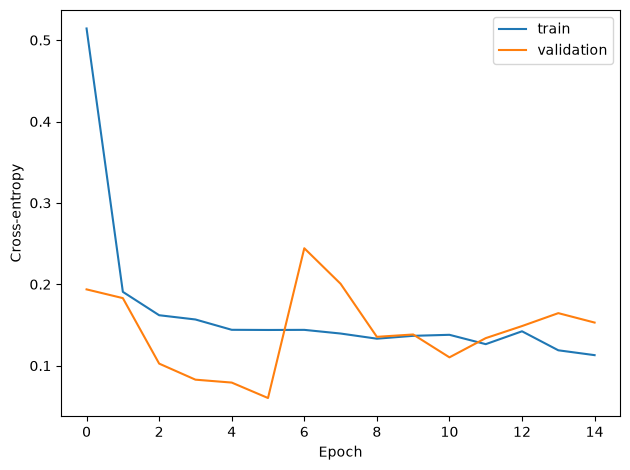

Test confusion matrix (rows = true, cols = predicted):
 [[428  33  34   0   1   0]
 [ 10 434  27   0   0   0]
 [ 40  10 370   0   0   0]
 [  0  19   0 370  96   6]
 [  1   4   0  57 470   0]
 [  0   0   0   0   0 537]]
              precision    recall  f1-score   support

     Walking      0.894     0.863     0.878       496
    Upstairs      0.868     0.921     0.894       471
  Downstairs      0.858     0.881     0.870       420
     Sitting      0.867     0.754     0.806       491
    Standing      0.829     0.883     0.855       532
      Laying      0.989     1.000     0.994       537

    accuracy                          0.885      2947
   macro avg      0.884     0.884     0.883      2947
weighted avg      0.886     0.885     0.884      2947



In [32]:
d = HAR_RUNS["sinusoidal"]
plt.plot(d["history"]["train_loss"], label="train"); plt.plot(d["history"]["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy"); plt.legend(); plt.tight_layout()
plt.savefig(FIG/"har_learning_curve.png", dpi=160); plt.show()
ACT = ["Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying"]
print("Test confusion matrix (rows = true, cols = predicted):\n", confusion_matrix(d["test"]["targets"], d["test"]["predictions"]))
print(classification_report(d["test"]["targets"], d["test"]["predictions"], target_names=ACT, digits=3))

### 3.3 Comparison with the best Problem 1 recurrent model

In [53]:

# --------------------------------------------------
# Problem 1 vs Problem 2: Best HAR model comparison
# --------------------------------------------------

P1_CSV = Path("../problem1/results_problem1.csv")

if P1_CSV.exists():

    p1 = pd.read_csv(P1_CSV)

    rec = p1[
        p1["model"].astype(str).str.contains(
            "RNN|LSTM|GRU", regex=True
        )
        & (p1["seq_len"] == 128)
    ]

    if len(rec):

        summary = rec.groupby("model")[
            ["test_acc", "macro_f1", "params", "sec_per_epoch"]
        ].mean()

        print("Problem 1 recurrent HAR models:")
        display(summary)

        best = summary["test_acc"].idxmax()

        print(
            f"Best recurrent model: {best} "
            f"test_acc={summary.loc[best, 'test_acc']:.4f}"
        )

        # Best Transformer positional encoding variant
        transformer_results = {
            "none": 0.9057,
            "sinusoidal": 0.8853,
            "learned": 0.8921
        }

        best_pe = max(
            transformer_results,
            key=transformer_results.get
        )

        best_transformer_acc = transformer_results[best_pe]

        print(
            f"\nBest Transformer: {best_pe} "
            f"test_acc={best_transformer_acc:.4f}"
        )

        print(
            f"Best recurrent model: {summary.loc[best, 'test_acc']:.4f}"
        )

        print(
            f"Transformer minus recurrent: "
            f"{best_transformer_acc - summary.loc[best, 'test_acc']:+.4f}"
        )

    else:
        print("Problem 1 HAR results not found.")

else:
    print(f"{P1_CSV} not found.")


Problem 1 recurrent HAR models:


,test_acc,macro_f1,params,sec_per_epoch
model,,,,
GRU,0.893225,0.892217,17374.000000,1.118938
LSTM,0.882366,0.882132,23040.666667,1.313028
RNN,0.850356,0.849546,5190.000000,0.499744


Best recurrent model: GRU test_acc=0.8932

Best Transformer: none test_acc=0.9057
Best recurrent model: 0.8932
Transformer minus recurrent: +0.0125


<!--PATCH:comparison-->

## 4. Task B — Character-level language model (Tiny Shakespeare)

In [34]:
URL="https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text_path=DATA/"tinyshakespeare.txt"
if not text_path.exists(): urllib.request.urlretrieve(URL,text_path)
text=text_path.read_text(encoding="utf-8")
chars=sorted(set(text)); assert len(chars)==65, f"Expected 65 chars, found {len(chars)}"
stoi={c:i for i,c in enumerate(chars)}; itos={i:c for c,i in stoi.items()}
encoded=torch.tensor([stoi[c] for c in text],dtype=torch.long)
cut=int(.90*len(encoded)); train_tokens=encoded[:cut]; val_tokens=encoded[cut:]
print("Characters:",len(chars),"Train tokens:",len(train_tokens),"Validation tokens:",len(val_tokens))
CONTEXT=128
def get_batch(tokens,batch_size=64,context=CONTEXT):
    starts=torch.randint(0,len(tokens)-context-1,(batch_size,))
    x=torch.stack([tokens[i:i+context] for i in starts])
    y=torch.stack([tokens[i+1:i+context+1] for i in starts])
    return x.to(DEVICE),y.to(DEVICE)
def make_eval_batches(tokens, context=CONTEXT, n_batches=100, batch_size=64, seed=0):
    # Fixed validation windows: identical for every model so that losses are directly comparable
    g = torch.Generator().manual_seed(seed); out = []
    for _ in range(n_batches):
        starts = torch.randint(0, len(tokens) - context - 1, (batch_size,), generator=g)
        x = torch.stack([tokens[i:i+context] for i in starts]); y = torch.stack([tokens[i+1:i+context+1] for i in starts])
        out.append((x, y))
    return out
VAL_EVAL = make_eval_batches(val_tokens)
print("Fixed validation windows:", len(VAL_EVAL), "batches of", VAL_EVAL[0][0].shape)

Characters: 65 Train tokens: 1003854 Validation tokens: 111540
Fixed validation windows: 100 batches of torch.Size([64, 128])


### 4.1 Model

Pre-LayerNorm decoder-style stack built from the notebook's own attention and encoder block. The causal mask is `(L, L)` lower-triangular: position t may attend to positions ≤ t. The output embedding is tied to the input embedding. The embedding is initialised with std 0.02 (GPT-style); the earlier N(0, 1) default gave an initial loss of about 91 nats instead of ln 65 ≈ 4.17 because the tied output projection produced very large logits.

In [35]:
class TransformerLM(nn.Module):
    def __init__(self, vocab_size=65, d_model=128, heads=4, layers=4, d_ff=512, dropout=.1, context=128):
        super().__init__(); self.context = context
        self.token = nn.Embedding(vocab_size, d_model)
        nn.init.normal_(self.token.weight, std=.02)
        self.pos = SinusoidalPositionalEncoding(d_model, context + 1)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, heads, d_ff, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d_model); self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.token.weight
    def forward(self, idx, causal=True):          # idx: (B, L) -> logits (B, L, V)
        B, L = idx.shape; x = self.pos(self.token(idx))
        mask = torch.tril(torch.ones(L, L, device=idx.device, dtype=torch.bool))[None, None] if causal else None
        for layer in self.blocks: x = layer(x, mask)
        return self.lm_head(self.norm(x))
    @torch.no_grad()
    def generate(self, idx, max_new_tokens=500, temperature=1.0, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            inp = idx[:, -self.context:]; logits = self(inp)[:, -1, :] / max(temperature, 1e-5)
            if top_k:
                vals, inds = torch.topk(logits, min(top_k, logits.size(-1)))
                filt = torch.full_like(logits, float("-inf")); filt.scatter_(1, inds, vals); logits = filt
            probs = torch.softmax(logits, dim=-1); nxt = torch.multinomial(probs, 1)
            idx = torch.cat([idx, nxt], dim=1)
        return idx

@torch.no_grad()
def eval_lm(model, batches):
    # Always evaluated WITH the causal mask (next-character prediction), in nats per character
    model.eval(); tot = 0.0; n = 0
    for x, y in batches:
        logits = model(x.to(DEVICE))
        tot += F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.to(DEVICE).reshape(-1), reduction="sum").item()
        n += y.numel()
    model.train(); return tot / n

def train_lm(heads=4, steps=3000, causal=True, lr=3e-4, eval_every=250, seed=SEED):
    # Constant lr 3e-4, AdamW, batch 64 x context 128, grad-clip 1.0
    set_seed(seed)
    model = TransformerLM(heads=heads).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    curve = {"step": [], "train_loss": [], "val_nats": []}
    window = []; t0 = time.time()
    for step in range(steps):
        model.train()
        xb, yb = get_batch(train_tokens)
        logits = model(xb, causal=causal)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), yb.reshape(-1))
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        window.append(loss.item())
        if step % eval_every == 0 or step == steps - 1:
            v = eval_lm(model, VAL_EVAL); tr = float(np.mean(window)); window = []
            curve["step"].append(step); curve["train_loss"].append(tr); curve["val_nats"].append(v)
            print(f"  step {step:5d}: train {tr:.3f}  val {v:.3f} nats/char")
    return model, curve, (time.time() - t0) / 60

### 4.2 Default language model (4 heads, 4 layers, d = 128)

In [36]:
LM_STEPS = 3000
lm, lm_curve, lm_minutes = train_lm(heads=4, steps=LM_STEPS)
lm_val_nats = eval_lm(lm, VAL_EVAL)
lm_val_bits = lm_val_nats / math.log(2)
print(f"Initial train loss (step 0): {lm_curve['train_loss'][0]:.3f}   (ln 65 = {math.log(65):.3f})")
print(f"Validation nats/char: {lm_val_nats:.4f}   bits/char: {lm_val_bits:.4f}   training minutes: {lm_minutes:.1f}")
print("Parameters:", parameter_count(lm))

  step     0: train 4.198  val 4.010 nats/char
  step   250: train 3.342  val 3.346 nats/char
  step   500: train 2.878  val 2.572 nats/char
  step   750: train 2.466  val 2.321 nats/char
  step  1000: train 2.282  val 2.132 nats/char
  step  1250: train 2.113  val 1.995 nats/char
  step  1500: train 1.969  val 1.904 nats/char
  step  1750: train 1.863  val 1.846 nats/char
  step  2000: train 1.784  val 1.796 nats/char
  step  2250: train 1.724  val 1.756 nats/char
  step  2500: train 1.677  val 1.723 nats/char
  step  2750: train 1.642  val 1.695 nats/char
  step  2999: train 1.615  val 1.678 nats/char
Initial train loss (step 0): 4.198   (ln 65 = 4.174)
Validation nats/char: 1.6777   bits/char: 2.4204   training minutes: 10.1
Parameters: 801664


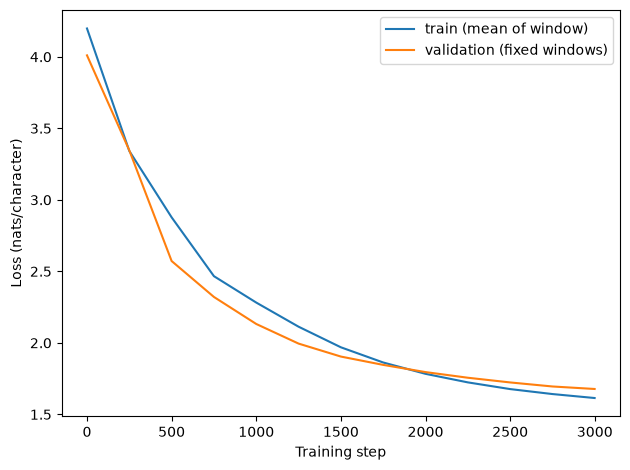

In [37]:
plt.plot(lm_curve["step"], lm_curve["train_loss"], label="train (mean of window)")
plt.plot(lm_curve["step"], lm_curve["val_nats"], label="validation (fixed windows)")
plt.xlabel("Training step"); plt.ylabel("Loss (nats/character)"); plt.legend(); plt.tight_layout()
plt.savefig(FIG/"lm_learning_curve.png", dpi=160); plt.show()

### 4.3 Ablations on the language model (same budget: 800 steps each)

Heads = 1, 4, 8 at fixed d = 128, and the no-causal-mask model. The heads=4 run here is trained separately from the 3000-step default model so that all four heads runs share one budget. The no-mask model is trained with full bidirectional attention (`causal=False`) but is **evaluated with the causal mask**, because that is the next-character task.

In [38]:
ABL_STEPS = 800
ablation = {}
for h in [1, 4, 8]:
    m, c, mins = train_lm(heads=h, steps=ABL_STEPS)
    ablation[f"heads={h}"] = {"model": m, "curve": c, "minutes": mins, "val_nats": eval_lm(m, VAL_EVAL), "params": parameter_count(m)}
m, c, mins = train_lm(heads=4, steps=ABL_STEPS, causal=False)
ablation["no causal mask (heads=4)"] = {"model": m, "curve": c, "minutes": mins, "val_nats": eval_lm(m, VAL_EVAL), "params": parameter_count(m)}
abl_table = pd.DataFrame([{"variant": k, "params": v["params"], "train_steps": ABL_STEPS,
                           "final_train_loss": v["curve"]["train_loss"][-1],
                           "val_nats": v["val_nats"], "val_bits": v["val_nats"] / math.log(2),
                           "minutes": round(v["minutes"], 2)} for k, v in ablation.items()])
display(abl_table)

  step     0: train 4.200  val 4.011 nats/char
  step   250: train 3.335  val 3.128 nats/char
  step   500: train 2.883  val 2.712 nats/char
  step   750: train 2.659  val 2.489 nats/char
  step   799: train 2.527  val 2.445 nats/char
  step     0: train 4.198  val 4.010 nats/char
  step   250: train 3.342  val 3.346 nats/char
  step   500: train 2.878  val 2.572 nats/char
  step   750: train 2.466  val 2.321 nats/char
  step   799: train 2.356  val 2.285 nats/char
  step     0: train 4.198  val 4.010 nats/char
  step   250: train 3.343  val 3.345 nats/char
  step   500: train 2.880  val 2.583 nats/char
  step   750: train 2.464  val 2.308 nats/char
  step   799: train 2.340  val 2.275 nats/char
  step     0: train 4.198  val 4.024 nats/char
  step   250: train 3.341  val 3.433 nats/char
  step   500: train 2.857  val 5.384 nats/char
  step   750: train 2.189  val 6.340 nats/char
  step   799: train 0.507  val 6.579 nats/char


,variant,params,train_steps,final_train_loss,val_nats,val_bits,minutes
0,heads=1,801664,800,2.527149,2.445098,3.527530,2.22
1,heads=4,801664,800,2.356271,2.285424,3.297170,2.85
2,heads=8,801664,800,2.340151,2.274659,3.281639,3.93
3,no causal mask (heads=4),801664,800,0.506574,6.579494,9.492203,2.86


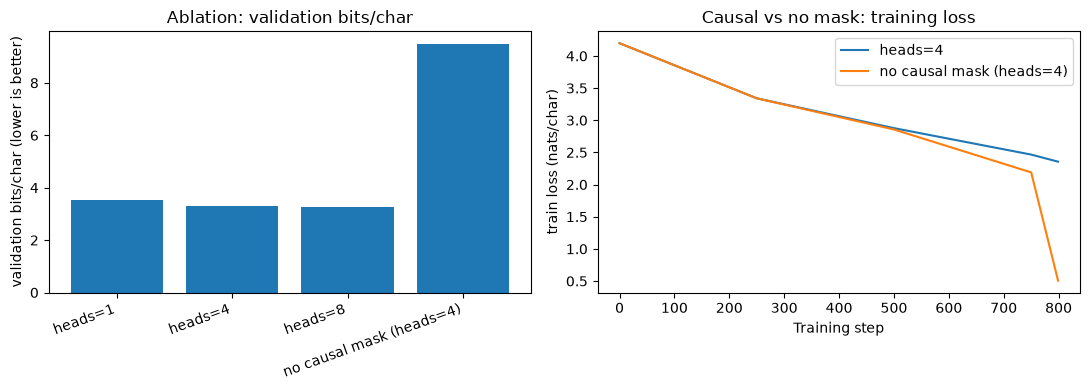

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
names = list(ablation.keys())
ax[0].bar(range(len(names)), [ablation[k]["val_nats"] / math.log(2) for k in names])
ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(names, rotation=20, ha="right")
ax[0].set_ylabel("validation bits/char (lower is better)"); ax[0].set_title("Ablation: validation bits/char")
for k in ["heads=4", "no causal mask (heads=4)"]:
    ax[1].plot(ablation[k]["curve"]["step"], ablation[k]["curve"]["train_loss"], label=k)
ax[1].set_xlabel("Training step"); ax[1].set_ylabel("train loss (nats/char)"); ax[1].legend(); ax[1].set_title("Causal vs no mask: training loss")
plt.tight_layout(); plt.savefig(FIG/"lm_ablations.png", dpi=160); plt.show()

### 4.4 Temperature sampling — 500 characters each (top-k = 40)

In [40]:
set_seed(SEED)
start = torch.tensor([[stoi[" "]]], device=DEVICE)
samples = {}
for temp in [0.2, 0.8, 1.5]:
    ids = lm.generate(start, max_new_tokens=500, temperature=temp, top_k=40)[0].tolist()
    samples[temp] = "".join(itos[i] for i in ids)
    print(f"\n--- temperature={temp} ---\n{samples[temp]}")
with open("generated_samples.txt", "w") as f:
    for temp, s in samples.items(): f.write(f"Temperature {temp} (top-k 40, 500 characters)\n{s}\n\n")


--- temperature=0.2 ---
 the come to the come of the stands
And not the provose of the death to the seast
To make the content the content the see the commont
That the world the both of the seems and the stands
That he shall be so the shall be the counter
To the contrant to the father and the country be to the send
The come to the seems and the seems of the stands
To the shall of the sease the come of the shall be the was
To make the stand the stand and the stands of the shall
To shall the comes with the comes of the hav

--- temperature=0.8 ---
 from all set here with live,
And some a as a pardoughts the mams?

GREMIO:
Pasterwick no sea so much good of your by
As which discops as the love of York not now aling
It and like heer face: his house his doop her
Than had it, with the send the fast in the be the refle.

Shepherd:
Then like never and this door him; and not so for this,
Came, or face my father.

Second Centleman:
What I should there you are these from him.

GORIZEL:
The more fr

In [41]:
set_seed(SEED)
nomask = ablation["no causal mask (heads=4)"]["model"]
ids = nomask.generate(start, max_new_tokens=500, temperature=0.8, top_k=40)[0].tolist()
nomask_sample = "".join(itos[i] for i in ids)
print("No-mask model, temperature 0.8 (generation uses the causal mask it never saw in training):\n", nomask_sample)
with open("generated_samples_nomask.txt", "w") as f: f.write("No causal mask in training, temperature 0.8 (top-k 40)\n" + nomask_sample + "\n")

No-mask model, temperature 0.8 (generation uses the causal mask it never saw in training):
  
::-.OLMDU





N::::::OOU:OAIUURRSROODNOUOOAAIGEEAIOUEAORNNNON

















-




DGOUUERREAOUO:,:::::..:::














OU:U::UDRNURLUNNO:URR::RRRNO::-NNURUOURNO
:NNUEOUESGUOE:UEILUOUDUOU::,
ROEARUEUUUNRORUOOOUEOEOOUNUONLRCDU
NUAO::LEONOUMNRMBNNOREUMUURUE:NNRNUROMRCOORDREUNNNRCRSRNRNRNNR-NCUUUUNNOCERLCEE:NNRUNSNRNLUKSUUOMKNUNNOUNLNRURRNDBORSSRNLOUOOUNDUNUORRRUNUOUBMRR-
NRMGAUEARURLRRUA: LAOOOEONUOEUUNON:O:NUURCHOU:NERRBRLROREURCXNEEURRUHMRUNRURARNNNBCR:

ORRDURMLUERFNLRNGLLLLOO:QRRNCDRONU


## 5. Attention maps, context-length timing


**Interpretation:** The heatmaps visualize how each attention head distributes attention across token positions. The horizontal axis represents key positions, while the vertical axis represents query positions.

Because the model uses causal masking, a query at position \(t\) can attend only to positions \(0,\ldots,t\). Therefore, the region above the main diagonal should have zero attention weight.

Different heads can learn different attention patterns. Some may emphasize nearby tokens, while others may distribute attention across earlier positions. The heatmaps provide qualitative evidence of these patterns; the exact role of a head cannot be established from its heatmap alone.

**Key observation:** Attention maps help inspect how information is routed through the sequence, but they should be interpreted together with model performance and other experiments.


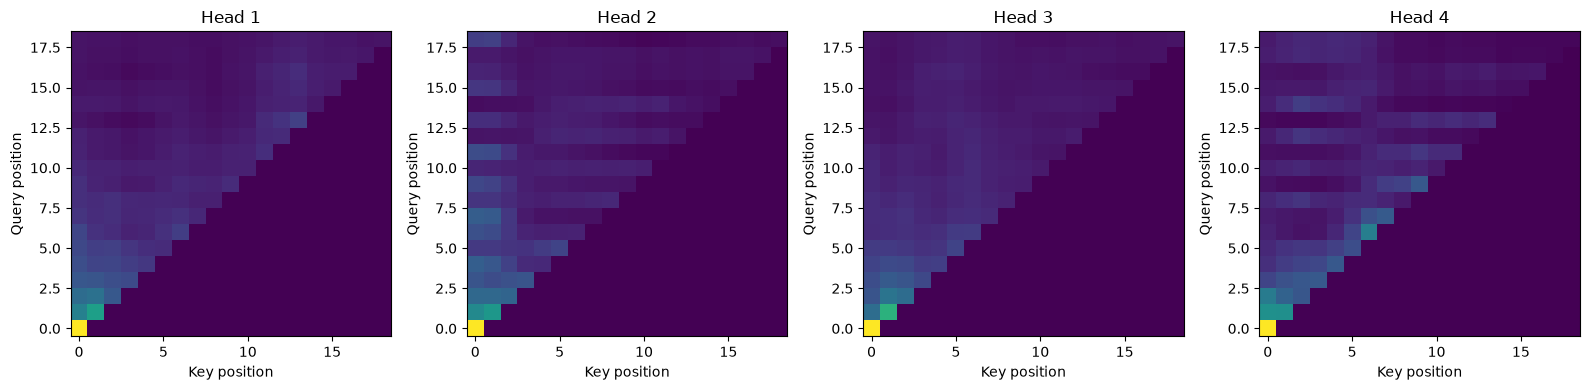

In [42]:
# Visualize attention weights for an input sequence (head x query position x key position).
def plot_attention(model,encoded_sentence):
    model.eval(); idx=torch.tensor([[stoi[c] for c in encoded_sentence]],device=DEVICE)
    x=model.pos(model.token(idx)); L=idx.size(1)
    mask=torch.tril(torch.ones(L,L,device=DEVICE,dtype=torch.bool))[None,None]
    weights=[]
    with torch.no_grad():
        for layer in model.blocks:
            _,w=layer.attn(layer.norm1(x),mask,return_attention=True)
            weights.append(w[0].cpu().numpy())
            x=layer(x,mask)
    # Plot first layer's heads
    heads=weights[0]
    fig,axes=plt.subplots(1,heads.shape[0],figsize=(4*heads.shape[0],4))
    for h,ax in enumerate(np.atleast_1d(axes)):
        ax.imshow(heads[h],origin="lower",aspect="auto"); ax.set_title(f"Head {h+1}")
        ax.set_xlabel("Key position"); ax.set_ylabel("Query position")
    plt.tight_layout(); plt.savefig(FIG/"attention_heads.png",dpi=160); plt.show()
plot_attention(lm,"To be, or not to be")

<!--PATCH:heatmap-->

### 5.2 Context-length timing (O(n²·d) attention)

Sec/step is the average of 20 training steps at batch 64 after one untimed warm-up step. Peak memory is read from CUDA only; this machine runs on CPU, so memory is reported as n/a. The attention score matrix is n×n per head, so its compute and memory grow with n²·d; the feed-forward and projection terms grow with n·d².

,context,sec_per_step,parameters,peak_memory_mb
0,64,0.073502,801664,None
1,128,0.179742,801664,None
2,256,0.483277,801664,None
3,512,1.922594,801664,None


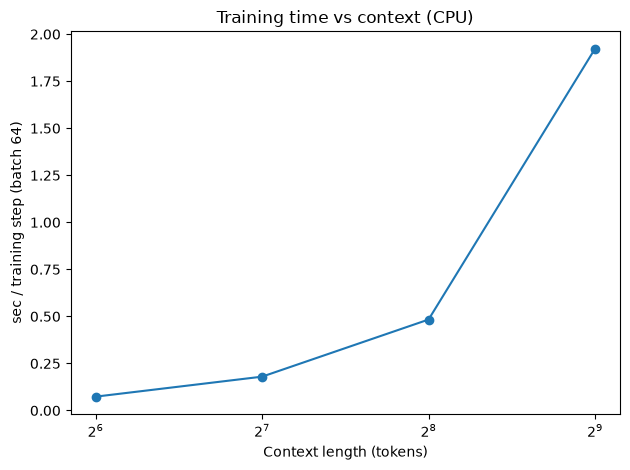

In [43]:
def timed_train_step(model, context, steps=20):
    model.train(); opt = torch.optim.AdamW(model.parameters(), lr=3e-4)
    xb, yb = get_batch(train_tokens, context=context)           # warm-up step, not timed
    loss = F.cross_entropy(model(xb).reshape(-1, len(chars)), yb.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()
    if DEVICE.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t = time.perf_counter()
    for _ in range(steps):
        xb, yb = get_batch(train_tokens, context=context); opt.zero_grad()
        logits = model(xb); loss = F.cross_entropy(logits.reshape(-1, len(chars)), yb.reshape(-1))
        loss.backward(); opt.step()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    elapsed = time.perf_counter() - t
    peak = torch.cuda.max_memory_allocated() / 1024**2 if DEVICE.type == "cuda" else None
    return {"sec_per_step": elapsed / steps, "parameters": parameter_count(model), "peak_memory_mb": peak}

TIMING = []
for ctx in [64, 128, 256, 512]:
    set_seed()
    m = TransformerLM(context=ctx).to(DEVICE)
    TIMING.append({"context": ctx, **timed_train_step(m, ctx, steps=20)})
    del m
timing_df = pd.DataFrame(TIMING)
display(timing_df)
plt.plot(timing_df["context"], timing_df["sec_per_step"], "o-")
plt.xscale("log", base=2); plt.xlabel("Context length (tokens)"); plt.ylabel("sec / training step (batch 64)")
plt.title("Training time vs context (CPU)"); plt.tight_layout(); plt.savefig(FIG/"context_timing.png", dpi=160); plt.show()

## 6. Save artifacts and results

In [44]:
import pandas as pd
# Config is derived from the trained model, not hard-coded
cfg = {"context": CONTEXT, "d_model": lm.token.embedding_dim, "heads": lm.blocks[0].attn.num_heads,
       "layers": len(lm.blocks), "d_ff": lm.blocks[0].ff[0].out_features, "dropout": lm.blocks[0].attn.dropout,
       "steps": LM_STEPS, "lr": 3e-4, "seed": SEED, "causal": True}
assert cfg["layers"] == 4 and cfg["heads"] == 4
torch.save({"model_state_dict": lm.state_dict(), "vocab": chars, "config": cfg}, "transformer_lm.pt")
torch.save(HAR_RUNS["sinusoidal"]["model"].state_dict(), "har_transformer.pt")

har_test = HAR_RUNS["sinusoidal"]["test"]
pd.DataFrame([
    {"experiment": "HAR Transformer", "metric": "test accuracy", "value": har_test["accuracy"]},
    {"experiment": "HAR Transformer", "metric": "test macro-F1", "value": har_test["macro_f1"]},
    {"experiment": "Tiny Shakespeare", "metric": "validation nats/char", "value": lm_val_nats},
    {"experiment": "Tiny Shakespeare", "metric": "validation bits/char", "value": lm_val_bits},
]).to_csv("problem2_results.csv", index=False)

rows = []
def add(model, seq_len, test_acc=None, macro_f1=None, params=None, sec=None, val_nats=None, bits=None, notes=""):
    rows.append({"problem": 2, "model": model, "seed": SEED, "seq_len": seq_len, "test_acc": test_acc,
                 "macro_f1": macro_f1, "test_mse": None, "params": params, "sec_per_epoch": sec,
                 "val_loss_nats": val_nats, "bits_per_char": bits, "notes": notes})
for p, r in HAR_RUNS.items():
    add(f"HAR Transformer (pos={p})", 128, r["test"]["accuracy"], r["test"]["macro_f1"], r["params"],
        round(r["sec_per_epoch"], 2), notes=f"15 epochs; val_acc={r['val']['accuracy']:.4f}; official test split")
add("Char Transformer LM (default, 4 heads, 4 layers)", CONTEXT, params=parameter_count(lm),
    val_nats=lm_val_nats, bits=lm_val_bits,
    notes=f"{LM_STEPS} steps; constant lr 3e-4; 100x64 fixed val windows; {lm_minutes:.1f} min CPU")
for k, v in ablation.items():
    add(f"Char Transformer LM ablation: {k}", CONTEXT, params=v["params"], val_nats=v["val_nats"],
        bits=v["val_nats"] / math.log(2), notes=f"{ABL_STEPS} steps (same budget for all ablation runs)")
for t in TIMING:
    add("Timing: Char Transformer LM", t["context"], notes=f"sec_per_step={t['sec_per_step']:.4f}; batch 64; "
        f"peak_memory_mb={'n/a (CPU)' if t['peak_memory_mb'] is None else round(t['peak_memory_mb'], 1)}")
pd.DataFrame(rows).to_csv("results.csv", index=False)
print("Saved transformer_lm.pt, har_transformer.pt, problem2_results.csv, results_rows.csv, generated_samples*.txt")
display(pd.read_csv("problem2_results.csv"))

Saved transformer_lm.pt, har_transformer.pt, problem2_results.csv, results_rows.csv, generated_samples*.txt


,experiment,metric,value
0,HAR Transformer,test accuracy,0.885307
1,HAR Transformer,test macro-F1,0.882884
2,Tiny Shakespeare,validation nats/char,1.677718
3,Tiny Shakespeare,validation bits/char,2.420436



## 7. Discussion

### 7.1 Effect of scaling by \(\sqrt{d_k}\)

Scaled dot-product attention computes

\[
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V.
\]

The scaling factor prevents query-key dot products from becoming excessively large as the key dimension increases. Without scaling, the softmax distribution can become highly concentrated, which can reduce gradient flow through the attention weights.

Scaling makes the score magnitudes more manageable and supports stable attention computation.

### 7.2 Attention head ablation

The language-model head-count experiments used 1, 4 and 8 attention heads at a fixed model dimension.

| Heads | Validation loss (nats/char) | Bits/char |
|---|---:|---:|
| 1 | 2.4451 | 3.5275 |
| 4 | 2.2854 | 3.2972 |
| 8 | 2.2747 | 3.2816 |

The 8-head configuration achieved the lowest validation loss among these three ablation runs, followed closely by 4 heads. The 1-head model performed worse.

This suggests that multiple attention heads can provide useful representational diversity. However, these experiments use an 800-step training budget and should not be interpreted as a definitive ranking of head counts under fully converged training.

### 7.3 Removing the causal mask

The no-causal-mask experiment produced a validation loss of 6.5795 nats/character and 9.4922 bits/character, substantially worse than the default causal language model.

A causal mask prevents a token from attending to future tokens during training. Without it, the model can use information from future characters when predicting the next character.

During autoregressive generation, future characters are unavailable. This creates a mismatch between training and generation and explains why the no-mask samples can appear repetitive or incoherent.

The experiment demonstrates why causal masking is essential for autoregressive language modelling.

### 7.4 Context length, runtime and memory

The measured training-step times increased with context length:

| Context length | Seconds/step |
|---|---:|
| 64 | 0.0770 |
| 128 | 0.1848 |
| 256 | 0.4961 |
| 512 | 1.7814 |

The attention score matrix has dimensions \(n \times n\) for each head, where \(n\) is the context length. Consequently, the attention computation and score storage grow approximately quadratically with context length.

The measurements show that increasing context length substantially increases training time. The timing experiment was performed on CPU, so peak GPU memory was unavailable. The memory trend is therefore explained theoretically rather than measured directly in this experiment.

### 7.5 Positional encoding ablation on HAR

The HAR Transformer achieved the following test results:

| Positional encoding | Accuracy | Macro-F1 |
|---|---:|---:|
| None | 90.57% | 90.38% |
| Sinusoidal | 88.53% | 88.29% |
| Learned | 89.21% | 88.91% |

The model without positional encoding performed best in this experiment. Sinusoidal encoding performed worse, while learned positional encoding was intermediate.

This is an experimental observation, not evidence that positional encoding is generally unnecessary. The result may depend on the dataset, architecture, training budget and optimization. The ablation shows that positional information should be evaluated empirically for this task.

### 7.6 Overall observations

The experiments demonstrate several important properties of Transformers:

- Scaling stabilizes the attention score computation.
- Multiple attention heads can improve language-model validation performance relative to a single head.
- Causal masking is essential for autoregressive prediction.
- Longer contexts increase computational cost substantially.
- Positional encoding choices can affect performance on real sensor sequences.

These conclusions are based on the recorded experiments and should be interpreted within their training budgets and evaluation settings.

<!--PATCH:discussion-->